In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install feature-engine

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install matplotlib_inline

Note: you may need to restart the kernel to use updated packages.


In [6]:
%pip install kagglehub

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib_inline
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler, OneHotEncoder, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error,mean_absolute_error
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.feature_selection import SelectFromModel, SelectKBest

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("camnugent/california-housing-prices")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\adeol\.cache\kagglehub\datasets\camnugent\california-housing-prices\versions\1


In [9]:
data = pd.read_csv(path + "/housing.csv")

In [10]:
data.tail(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [11]:
data.shape

(20640, 10)

In [12]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [13]:
data.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [14]:
data.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
20635    False
20636    False
20637    False
20638    False
20639    False
Length: 20640, dtype: bool

In [15]:
data.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [16]:
percentage = data["total_bedrooms"].sum() / data["total_rooms"].sum() * 100
print(f"Bedrooms are {percentage:.2f}% of total rooms")

Bedrooms are 20.20% of total rooms


In [17]:
percentage

np.float64(20.201975473395812)

In [18]:
data.fillna(0, inplace=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [19]:
X =data.drop(["median_house_value"], axis=1, inplace=False)

In [20]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,NEAR BAY


In [21]:
y = data["median_house_value"]

In [22]:
y

0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 20640, dtype: float64

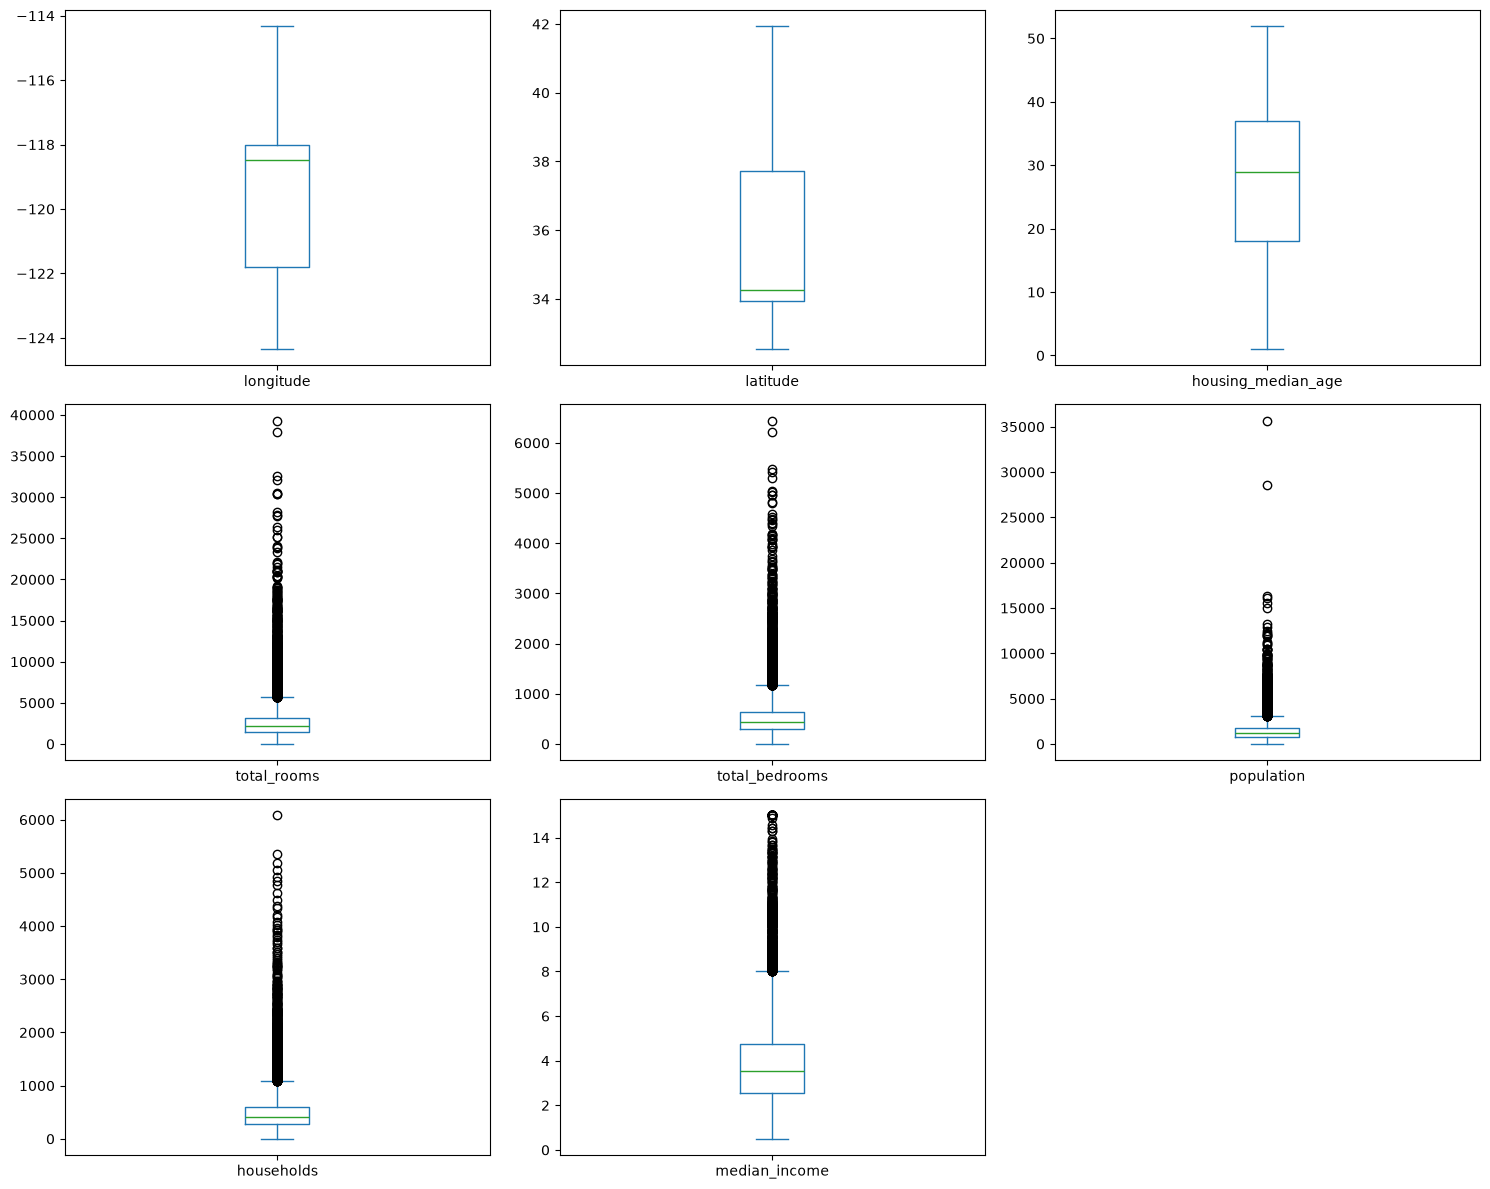

In [23]:


numeric_data = X.select_dtypes(include="number")

numeric_data.plot(
    kind="box",
    subplots=True,
    layout=(3, 3),
    figsize=(15, 12),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [24]:
numerical_cols = X.select_dtypes(include="number").columns
outlier_cols = []

for col in numerical_cols:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    has_outliers = ((X[col] < lower) | (X[col] > upper)).any()

    if has_outliers:
        outlier_cols.append(col)
        X[col] = X[col].clip(lower=lower, upper=upper)

print("Columns clipped:", outlier_cols)

Columns clipped: ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']


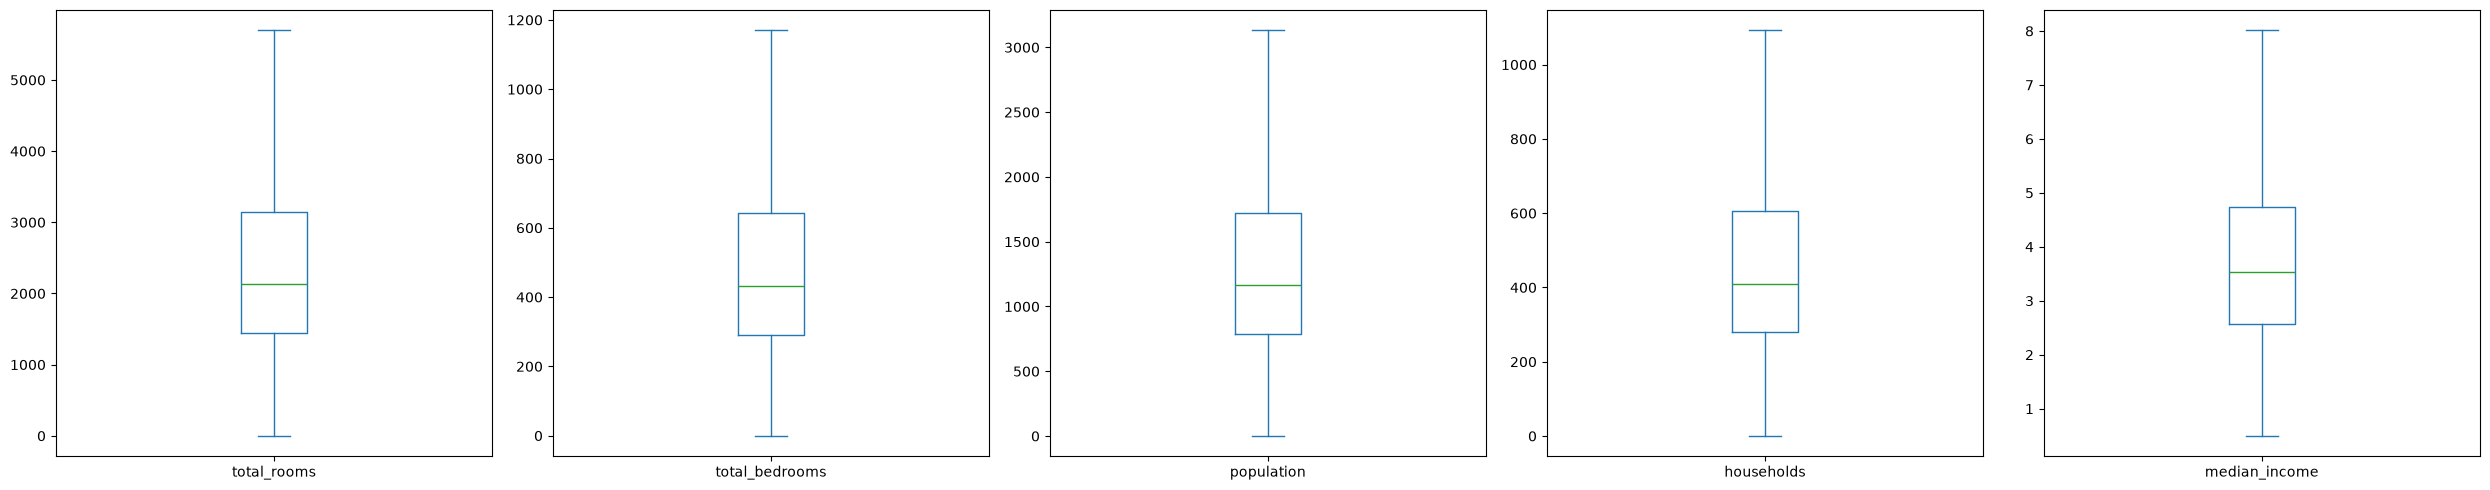

In [25]:
if outlier_cols:
    X[outlier_cols].plot(
        kind="box",
        subplots=True,
        layout=(1, len(outlier_cols)),
        figsize=(5 * len(outlier_cols), 5),
        sharey=False
    )
    plt.tight_layout()
    plt.show()
else:
    print("No outlier columns were found.")

In [26]:
%pip install mlflow

Note: you may need to restart the kernel to use updated packages.


In [27]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("http://localhost:5000")
client = MlflowClient()

In [28]:
EXPERIMENT = "California Housing Prices"

In [29]:
experiment = mlflow.set_experiment(EXPERIMENT)
experiment_tags = {
    "project": "California-Housing-value",
    "owner": "sheik",
    "dataset": "california-housing",
    "task": "continuous value prediction",
    "primary_metrics": "f1",
    "mlflow.note.content": "compare ML models and neural network on the same split",
}
mlflow.set_experiment_tags(experiment_tags)

print(f"Experiment: {experiment.name} (ID: {experiment.experiment_id})")
print("Experiment tags:")
for key, value in experiment_tags.items():
    print(f"  {key}: {value}")

Experiment: California Housing Prices (ID: 1)
Experiment tags:
  project: California-Housing-value
  owner: sheik
  dataset: california-housing
  task: continuous value prediction
  primary_metrics: f1
  mlflow.note.content: compare ML models and neural network on the same split


In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [31]:
%pip install feature-engine

Note: you may need to restart the kernel to use updated packages.


In [32]:
from feature_engine.outliers import Winsorizer

print("Import successful")

Import successful


In [33]:
capped = Winsorizer(capping_method="iqr", tail="both", fold=1.5, variables=outlier_cols)

In [34]:
X_train_capped = capped.fit_transform(X_train)
X_test_capped = capped.transform(X_test)

In [35]:
numeric_cols = X.select_dtypes(include="number").columns
categorical_cols = X.select_dtypes(include="object").columns

C:\Users\adeol\AppData\Local\Temp\ipykernel_34208\13732464.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns


In [36]:
Processor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(drop="first"), categorical_cols)
    ]
)

In [37]:
X_train_processed = Processor.fit_transform(X_train_capped)
X_test_processed = Processor.transform(X_test_capped)

In [38]:
def score(y_true, y_pred):
    return {
        "r2": float(r2_score(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": float(mean_absolute_error(y_true, y_pred)),
    }


def log_evaluation_metrics(y_true, y_pred, run_name="Actual vs. predicted values"):
    metrics = score(y_true, y_pred)

    for metric_name, metric_value in metrics.items():
        mlflow.log_metric(metric_name, metric_value)

    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(x=y_true, y=y_pred, ax=ax)

    ax.set_title(run_name, fontsize=16)
    ax.set_xlabel("Actual values")
    ax.set_ylabel("Predicted values")
    mlflow.log_figure(fig, "actual_vs_predicted.png")
    plt.close(fig)

    return metrics

In [39]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [40]:
from sklearn.neural_network import MLPRegressor

ML_MODEL = {
    "linearreg": (
        LinearRegression(),
        {
            "algorithm": "Linear Regression",
            "hyperparameters": {},
        },
    ),
    "randomforestreg": (
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
        ),
        {
            "algorithm": "Random Forest Regressor",
            "hyperparameters": {
                "n_estimators": 100,
                "random_state": 42,
                "n_jobs": -1,
            },
        },
    ),
    "gradientboostingreg": (
        GradientBoostingRegressor(
            n_estimators=100,
            random_state=42,
        ),
        {
            "algorithm": "Gradient Boosting Regressor",
            "hyperparameters": {
                "n_estimators": 100,
                "random_state": 42,
            },
        },
    ),
    "mlpregressor": (
        MLPRegressor(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.0001,
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=True,
            random_state=42,
        ),
        {
            "algorithm": "MLP Neural Network Regressor",
            "hyperparameters": {
                "hidden_layer_sizes": (64, 32),
                "activation": "relu",
                "solver": "adam",
                "alpha": 0.0001,
                "learning_rate_init": 0.001,
                "max_iter": 300,
                "early_stopping": True,
                "random_state": 42,
            },
        },
    ),
}

for model_key, (model, model_info) in ML_MODEL.items():
    algorithm = model_info["algorithm"]

    with mlflow.start_run(run_name=algorithm):
        mlflow.set_tag("algorithm", algorithm)
        mlflow.log_params(model_info["hyperparameters"])

        model.fit(X_train_processed, y_train)
        y_pred = model.predict(X_test_processed)

        metrics = log_evaluation_metrics(
            y_test,
            y_pred,
            run_name=algorithm,
        )

        print(f"{model_key} ({algorithm}): {metrics}")

linearreg (Linear Regression): {'r2': 0.5734084179351255, 'rmse': 74766.93381300327, 'mae': 53858.820015688565}
🏃 View run Linear Regression at: http://localhost:5000/#/experiments/1/runs/385656e8e2ea4829a9d710e1be033d36
🧪 View experiment at: http://localhost:5000/#/experiments/1
randomforestreg (Random Forest Regressor): {'r2': 0.8090277454651901, 'rmse': 50025.169358765925, 'mae': 32460.309089147282}
🏃 View run Random Forest Regressor at: http://localhost:5000/#/experiments/1/runs/81540cd70e6940e1bc8f0735cee51bf0
🧪 View experiment at: http://localhost:5000/#/experiments/1
gradientboostingreg (Gradient Boosting Regressor): {'r2': 0.7584943427255296, 'rmse': 56255.771400669255, 'mae': 38453.74918094879}
🏃 View run Gradient Boosting Regressor at: http://localhost:5000/#/experiments/1/runs/ae54dac6330e4b8aaad9de932aa466a6
🧪 View experiment at: http://localhost:5000/#/experiments/1


c:\WEEK2(DEEP_LEARNING)\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


mlpregressor (MLP Neural Network Regressor): {'r2': 0.6570860145235518, 'rmse': 67034.13796959781, 'mae': 47052.01866224258}
🏃 View run MLP Neural Network Regressor at: http://localhost:5000/#/experiments/1/runs/922291be6f2f4c0d893816cbe8f3a4af
🧪 View experiment at: http://localhost:5000/#/experiments/1
